# 01 · Excess Gibbs energy and custom models

**Requirements:** core package and tutorial plotting dependencies.

Run this notebook from top to bottom in the environment where ThermoWeave is installed. All examples are self-contained unless explicitly marked optional. See the [course index](../../tutorials.md) and [theory guide](../../theory.md).

<a class="md-button" href="custom_activity_models.ipynb" download>Download notebook</a>


## From a scalar free energy to activity coefficients
 For the pure-liquid standard state, $\mu_i=\mu_i^*+RT\ln(x_i\gamma_i)$.
 The total excess energy is $G^E=n g^E$ and
 $\ln\gamma_i=\partial(G^E/RT)/\partial n_i$ at fixed T, P and other mole numbers.
 For $g^E/(RT)=A x_1x_2$, the result is
 $\ln\gamma_1=A x_2^2$, $\ln\gamma_2=A x_1^2$.

 We choose synthetic A=1.5. This dimensionless A is constant in this example;
 it is not a temperature-independent energy parameter $\Omega$ with $A=\Omega/(RT)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from thermoweave import ThermodynamicModel
from thermoweave.model import mole_fractions

class RegularSolution(ThermodynamicModel):
    """Synthetic binary two-suffix Margules model; A is dimensionless."""
    def __init__(self, A=0.0):
        self.A = float(A)
    @property
    def n_components(self):
        return 2
    def ln_activity_coefficients(self, temperature_K, x, pressure_Pa=None):
        x = mole_fractions(x, 2)
        return self.A * np.array([x[1]**2, x[0]**2])

In [2]:
model = RegularSolution(A=1.5)
T, x = 298.15, np.array([0.3, 0.7])
lng = model.ln_activity_coefficients(T, x)
print('ln gamma:', lng, '; gamma:', np.exp(lng))
print('gE/RT:', model.reduced_excess_gibbs(T, x))
np.testing.assert_allclose(model.reduced_excess_gibbs(T, x), 1.5*x[0]*x[1])
step = 1e-6
direction = np.array([1.0, -1.0])
dlng_dx1 = (model.ln_activity_coefficients(T, x+step*direction)
            - model.ln_activity_coefficients(T, x-step*direction))/(2*step)
print('Gibbs-Duhem residual:', x @ dlng_dx1)
assert abs(x @ dlng_dx1) < 1e-8

ln gamma: [0.735 0.135] ; gamma: [2.08548199 1.14453678]
gE/RT: 0.31499999999999995
Gibbs-Duhem residual: -2.9143394364439244e-11


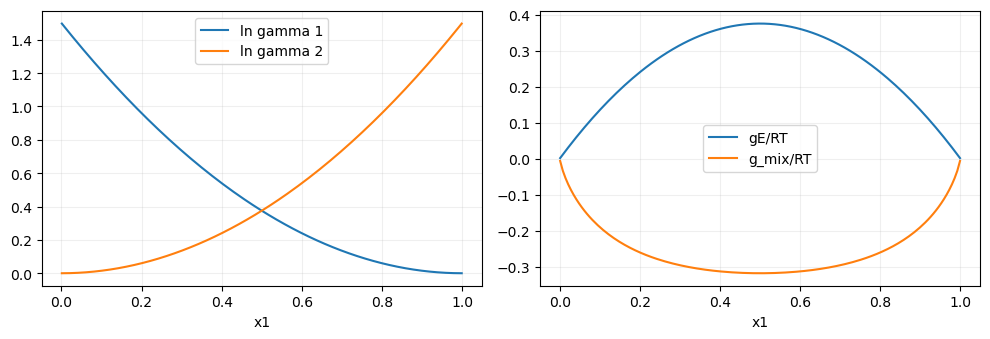

In [3]:
xs = np.linspace(0.001, 0.999, 150)
X = np.column_stack([xs, 1-xs])
lng = np.array([model.ln_activity_coefficients(T, z) for z in X])
ge = np.array([model.reduced_excess_gibbs(T, z) for z in X])
gm = np.array([model.reduced_mixing_gibbs(T, z) for z in X])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(xs, lng[:, 0], label='ln gamma 1'); ax[0].plot(xs, lng[:, 1], label='ln gamma 2')
ax[1].plot(xs, ge, label='gE/RT'); ax[1].plot(xs, gm, label='g_mix/RT')
for a in ax: a.set_xlabel('x1'); a.legend(); a.grid(alpha=0.2)
fig.tight_layout(); plt.show()

**Try:** vary A from 0 to 3. A larger positive excess energy can make the
 mixing energy nonconvex. Notebook 06 asks whether that homogeneous liquid is
 stable. The same solver interface works with SAFT, COSMO-RS or HANNA activities;
 only SAFT supplies the additional EOS properties.